## Kattegat A/B/E Route Structure and Lane Displacement (Flag 6)

### Dataset Overview
This derived case contains 47 AIS-like vessel trajectories in the Kattegat area, static vessel attributes, and directional reference-lane geometry for historical-style Routes A, B, and E. The trajectory table intentionally does not expose route assignments. Its A/B/E topology is derived from the official-transit-route layout in Figure 9-2 and the route descriptions in Sections 9.1–9.2 of risk_to_ship_traffic.pdf; vessel-type proportions and the directional transverse-distribution pattern follow the Chapter 9 route-analysis findings.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Analyze the given vessel trajectories and summarize the typical routes in this part of the Kattegat, together with their traffic characteristics.

Role: Maritime traffic analyst


Category: Kattegat route structure and transverse traffic distribution

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: What recurrent route corridors can be identified from the trajectory geometry and directional route-reference lanes in the selected Kattegat area?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

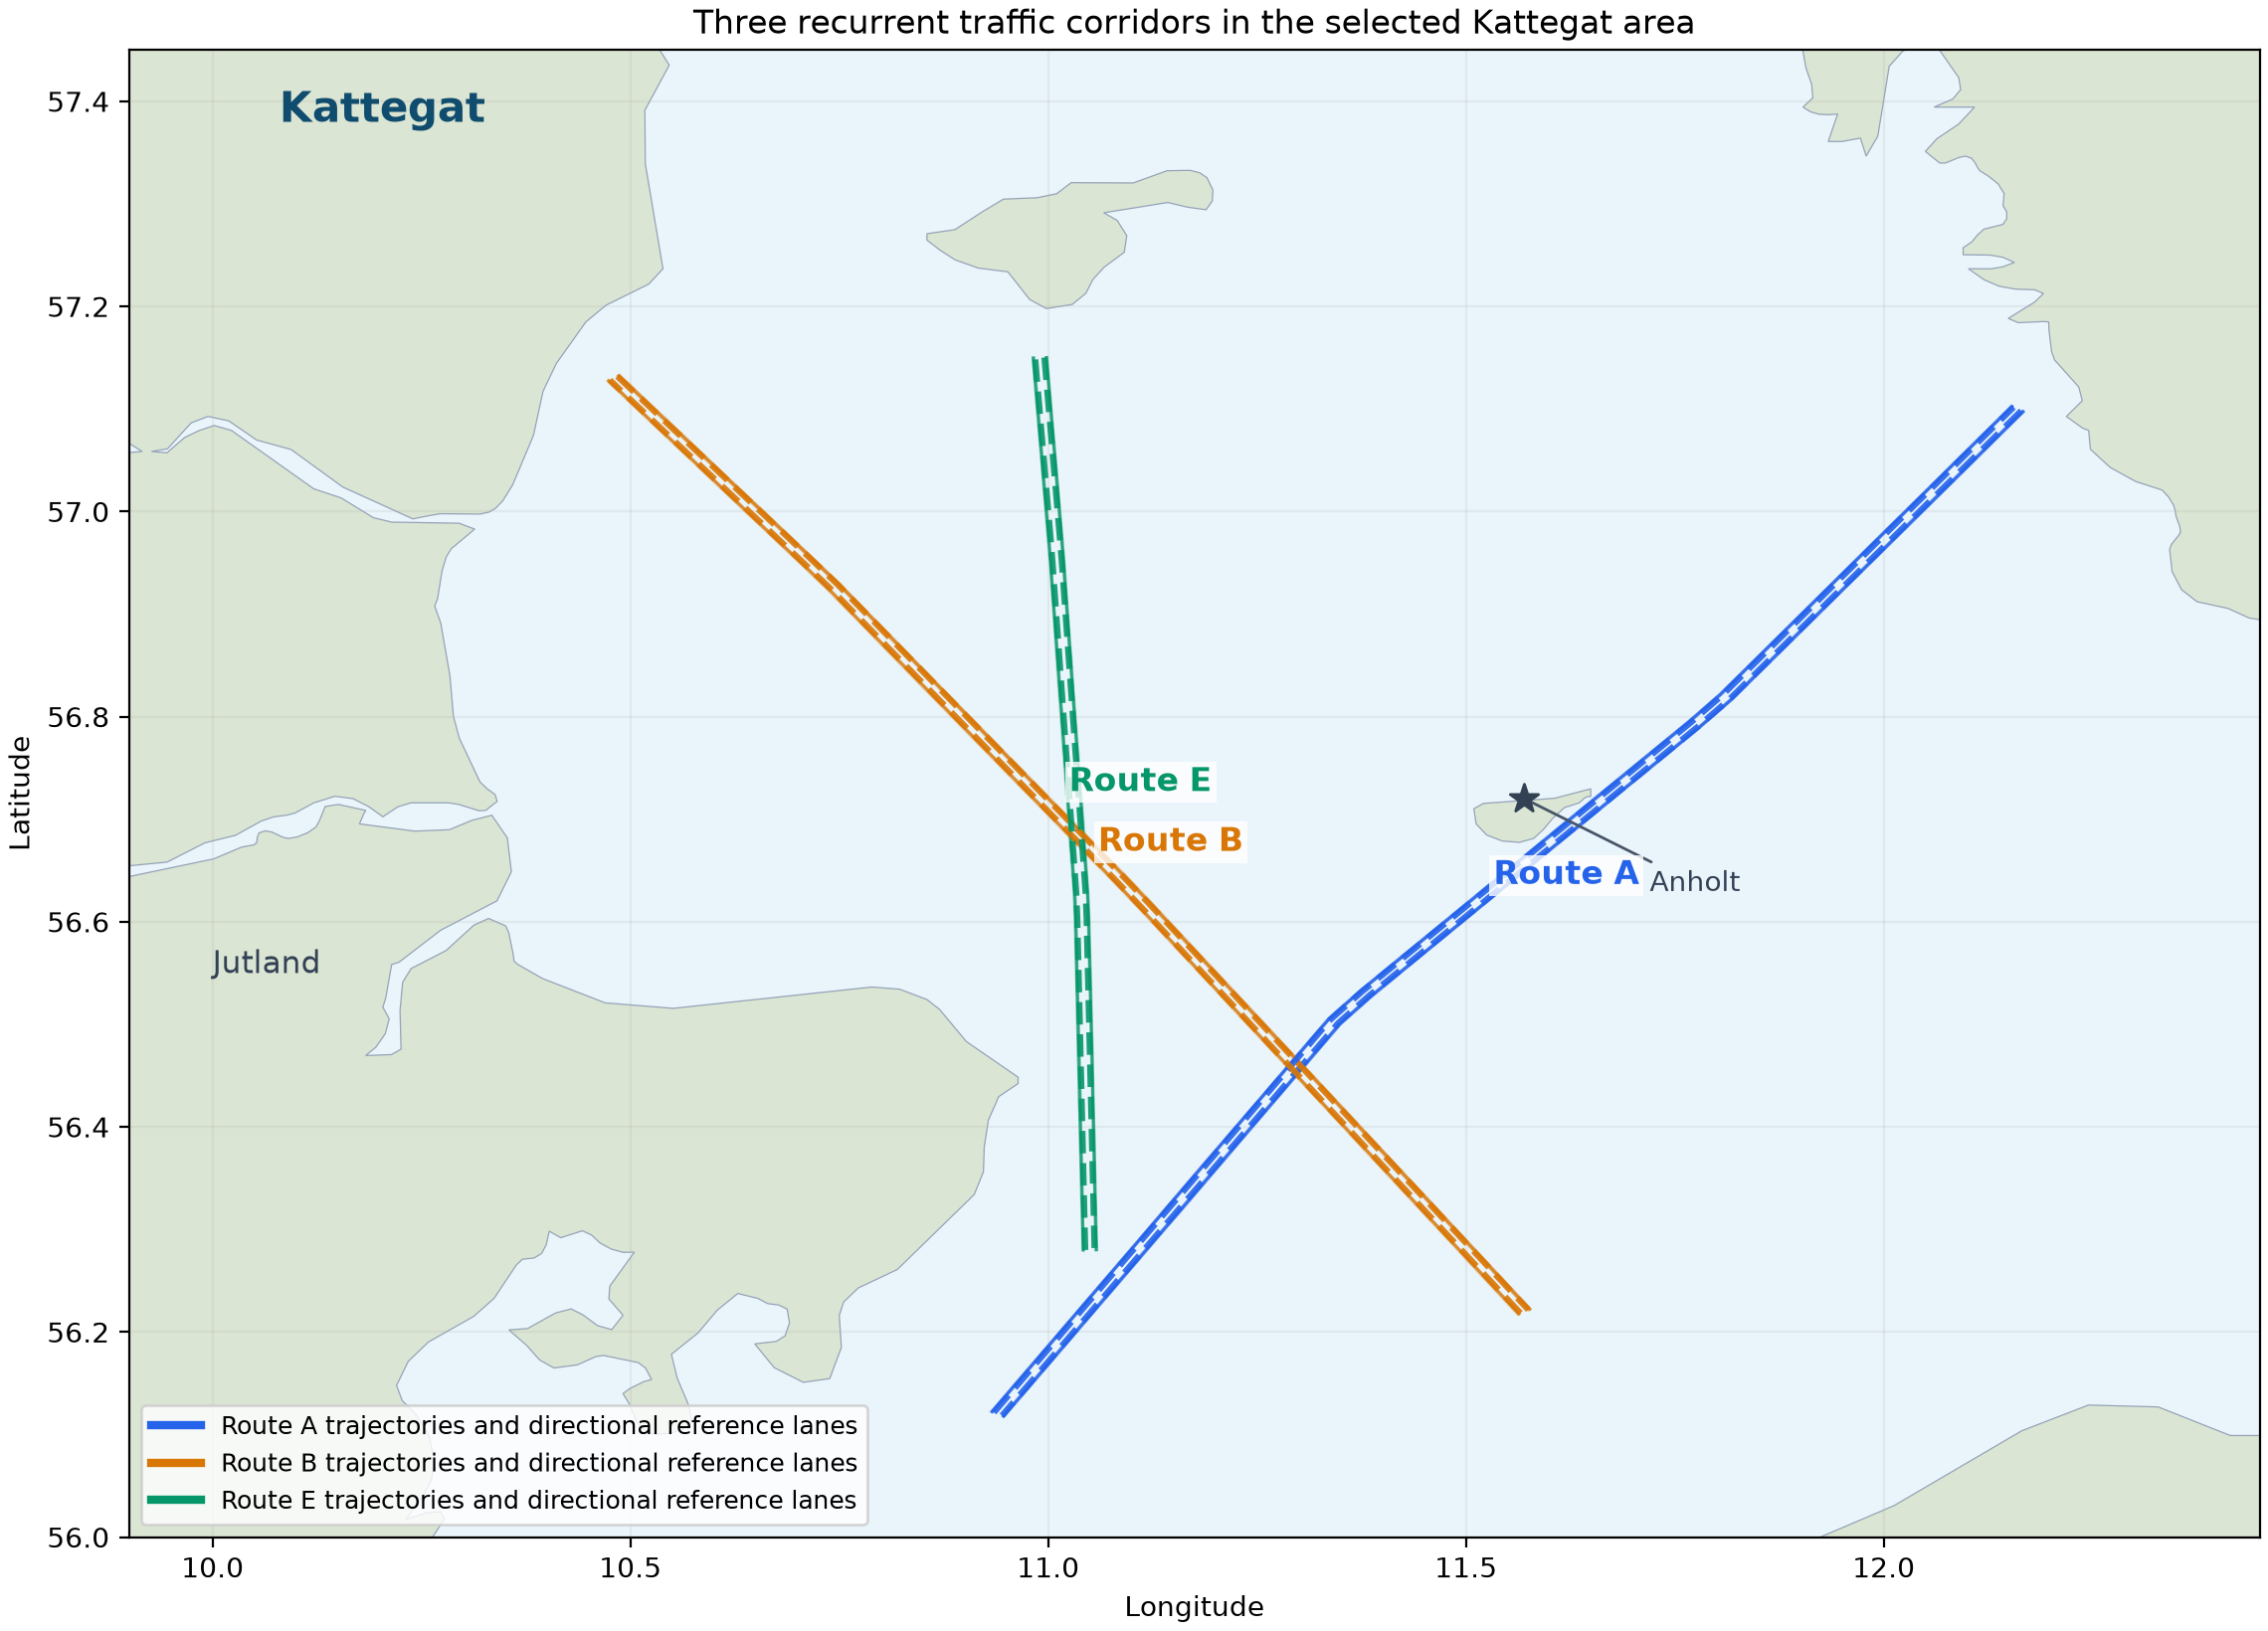

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
points = pd.read_csv(dataset_path)
lanes = pd.read_csv(Path('route_lanes.csv'))
print(points.groupby('trajectory_id').agg(vessel_id=('vessel_id','first'), start_time=('timestamp','min'), mean_cog=('cog','mean')))
for route, g in lanes.groupby('route_name'):
    plt.plot(g['lon'], g['lat'], '.', ms=2, label=f'Route {route} reference')
plt.scatter(points['lon'], points['lat'], s=1, alpha=.15)
plt.legend(); plt.axis('equal'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/kattegat_three_routes_map.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "route_structure",
  "insight": "Three recurrent bidirectional traffic corridors structure the selected Kattegat area: Route A follows a southwest–northeast corridor southeast of Anholt, Route B is a northwest–southeast cross-Kattegat corridor west of Anholt, and Route E follows a southwest–northeast corridor on the western side of the project area.",
  "insight_value": {
    "routes": {
      "A": "SW–NE southeast of Anholt",
      "B": "NW–SE west of Anholt",
      "E": "SW–NE west of the project area"
    },
    "trajectory_counts": {
      "A": 18,
      "B": 15,
      "E": 14
    }
  },
  "plot": {
    "plot_type": "geographic_route_map",
    "title": "Three Recurrent Kattegat Traffic Corridors",
    "file": "visualizations/kattegat_three_routes_map.png",
    "description": "Observed trajectories form three route families around Anholt. Dashed lines are the supplied directional reference-lane centrelines; route labels are not attached to trajectory points."
  },
  "question": "What recurrent route corridors can be identified from the trajectory geometry and directional route-reference lanes in the selected Kattegat area?",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nfrom pathlib import Path\npoints = pd.read_csv(dataset_path)\nlanes = pd.read_csv(Path('route_lanes.csv'))\nprint(points.groupby('trajectory_id').agg(vessel_id=('vessel_id','first'), start_time=('timestamp','min'), mean_cog=('cog','mean')))\nfor route, g in lanes.groupby('route_name'):\n    plt.plot(g['lon'], g['lat'], '.', ms=2, label=f'Route {route} reference')\nplt.scatter(points['lon'], points['lat'], s=1, alpha=.15)\nplt.legend(); plt.axis('equal'); plt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "route_reference_lane",
    "vessel_id"
  ]
}

### **Question 2**: After assigning trajectories to the three route corridors, how does vessel-type composition differ between Route A, Route B, and Route E?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

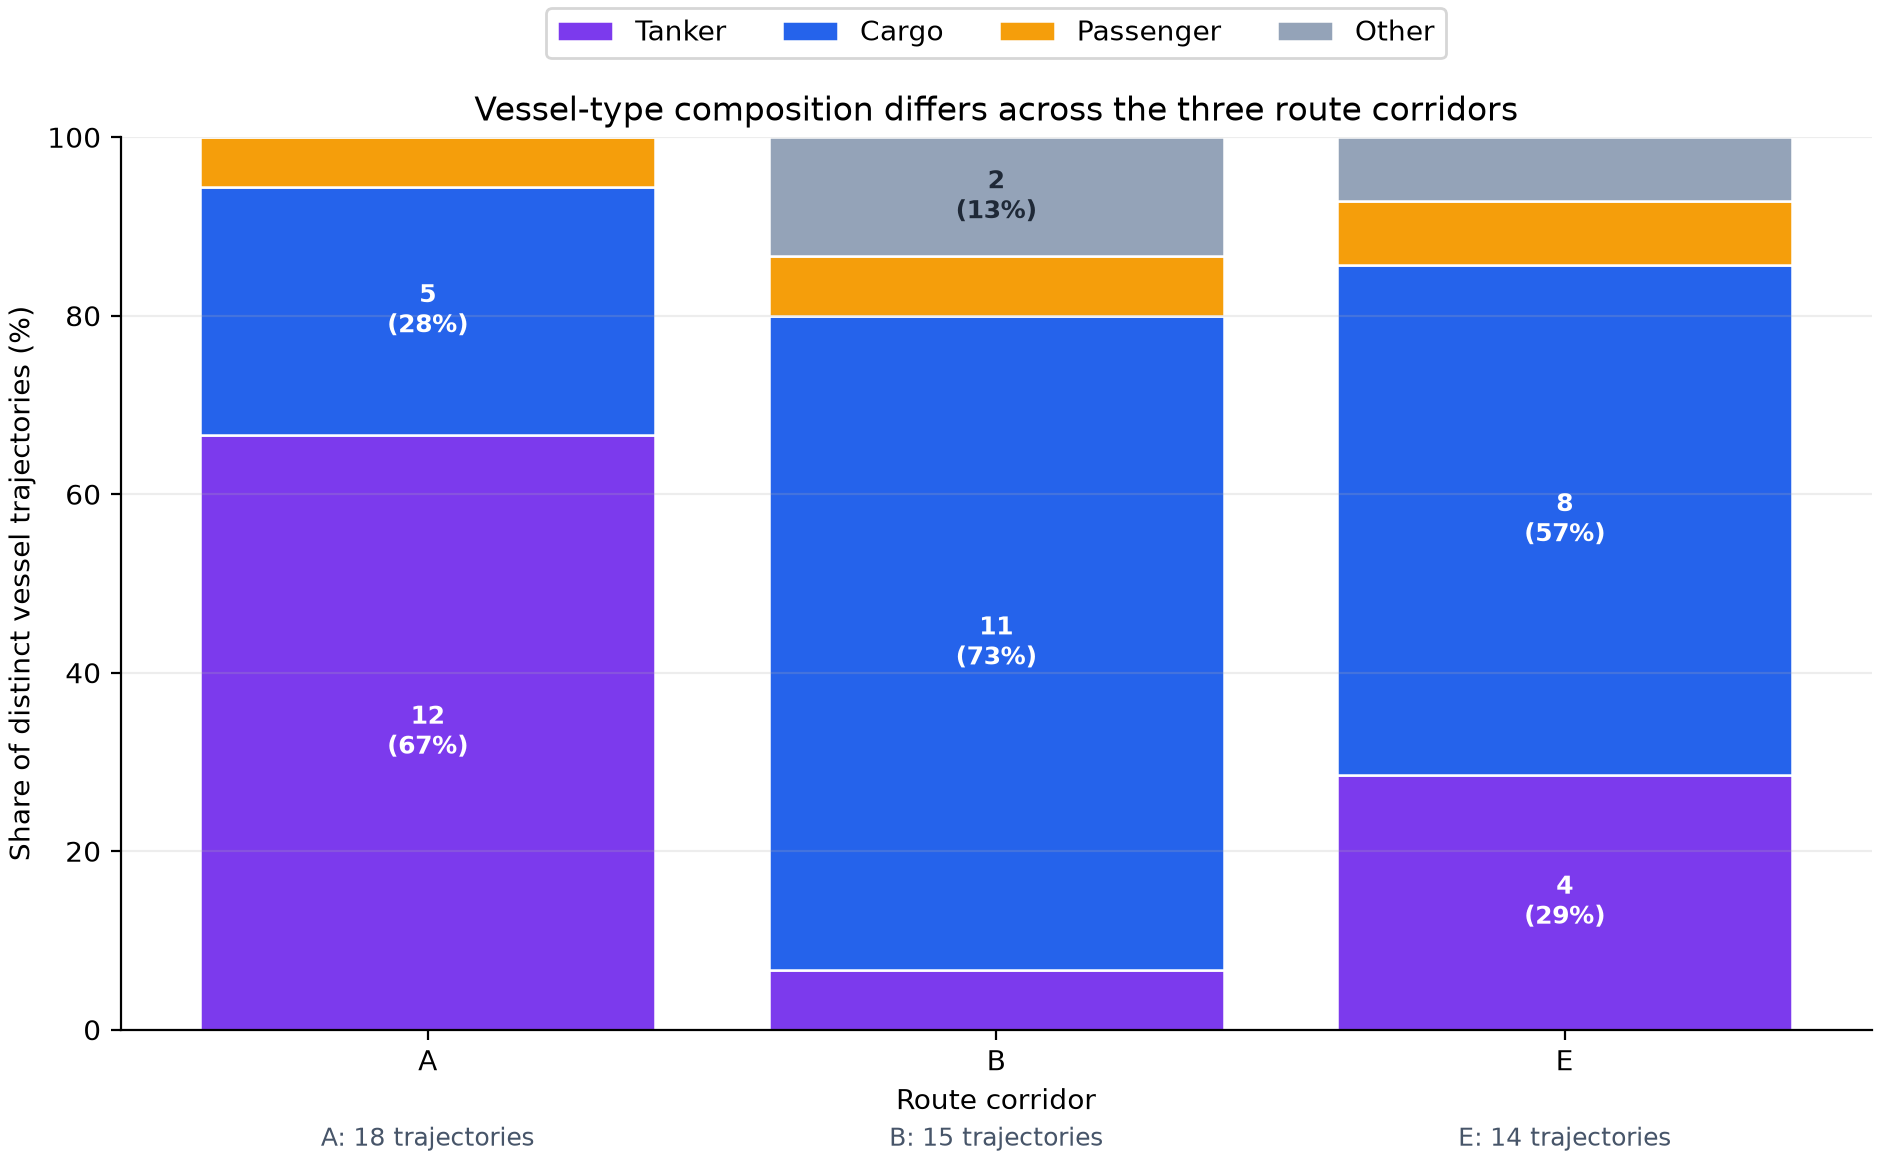

In [ ]:
import pandas as pd
from pathlib import Path
points = pd.read_csv(dataset_path)
vessels = pd.read_csv(user_dataset_path)
lanes = pd.read_csv(Path('route_lanes.csv'))
tracks = points.groupby('trajectory_id').agg(vessel_id=('vessel_id','first'), mean_lon=('lon','mean'), mean_lat=('lat','mean'), mean_cog=('cog','mean')).reset_index()
# Assign each track to the nearest compatible directional reference lane before merging vessel types.
print(tracks.merge(vessels[['vessel_id','ship_type']], on='vessel_id').groupby('ship_type').size())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/route_ship_type_composition.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "cross_source_composition",
  "insight": "Route A is tanker-dominated, with 12 of its 18 vessel trajectories classified as Tanker (67%). Cargo traffic is most pronounced on Route B (11 of 15 trajectories, 73%) and Route E (8 of 14 trajectories, 57%).",
  "insight_value": {
    "A": {
      "Tanker": 12,
      "Cargo": 5,
      "Passenger": 1
    },
    "B": {
      "Cargo": 11,
      "Tanker": 1,
      "Passenger": 1,
      "Other": 2
    },
    "E": {
      "Cargo": 8,
      "Tanker": 4,
      "Passenger": 1,
      "Other": 1
    }
  },
  "plot": {
    "plot_type": "composition_comparison",
    "title": "Vessel-Type Composition by Route Corridor",
    "file": "visualizations/route_ship_type_composition.png",
    "description": "The route assignment must be obtained from trajectory geometry and the reference lanes, then combined with vessel attributes by vessel_id."
  },
  "question": "After assigning trajectories to the three route corridors, how does vessel-type composition differ between Route A, Route B, and Route E?",
  "code": "import pandas as pd\nfrom pathlib import Path\npoints = pd.read_csv(dataset_path)\nvessels = pd.read_csv(user_dataset_path)\nlanes = pd.read_csv(Path('route_lanes.csv'))\ntracks = points.groupby('trajectory_id').agg(vessel_id=('vessel_id','first'), mean_lon=('lon','mean'), mean_lat=('lat','mean'), mean_cog=('cog','mean')).reset_index()\n# Assign each track to the nearest compatible directional reference lane before merging vessel types.\nprint(tracks.merge(vessels[['vessel_id','ship_type']], on='vessel_id').groupby('ship_type').size())",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "route_reference_lane",
    "ship_type",
    "vessel_id"
  ]
}

### **Question 3**: Are vessel tracks symmetrically distributed around the nominal centre of each directional lane, or do they show a systematic transverse displacement relative to opposing traffic?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

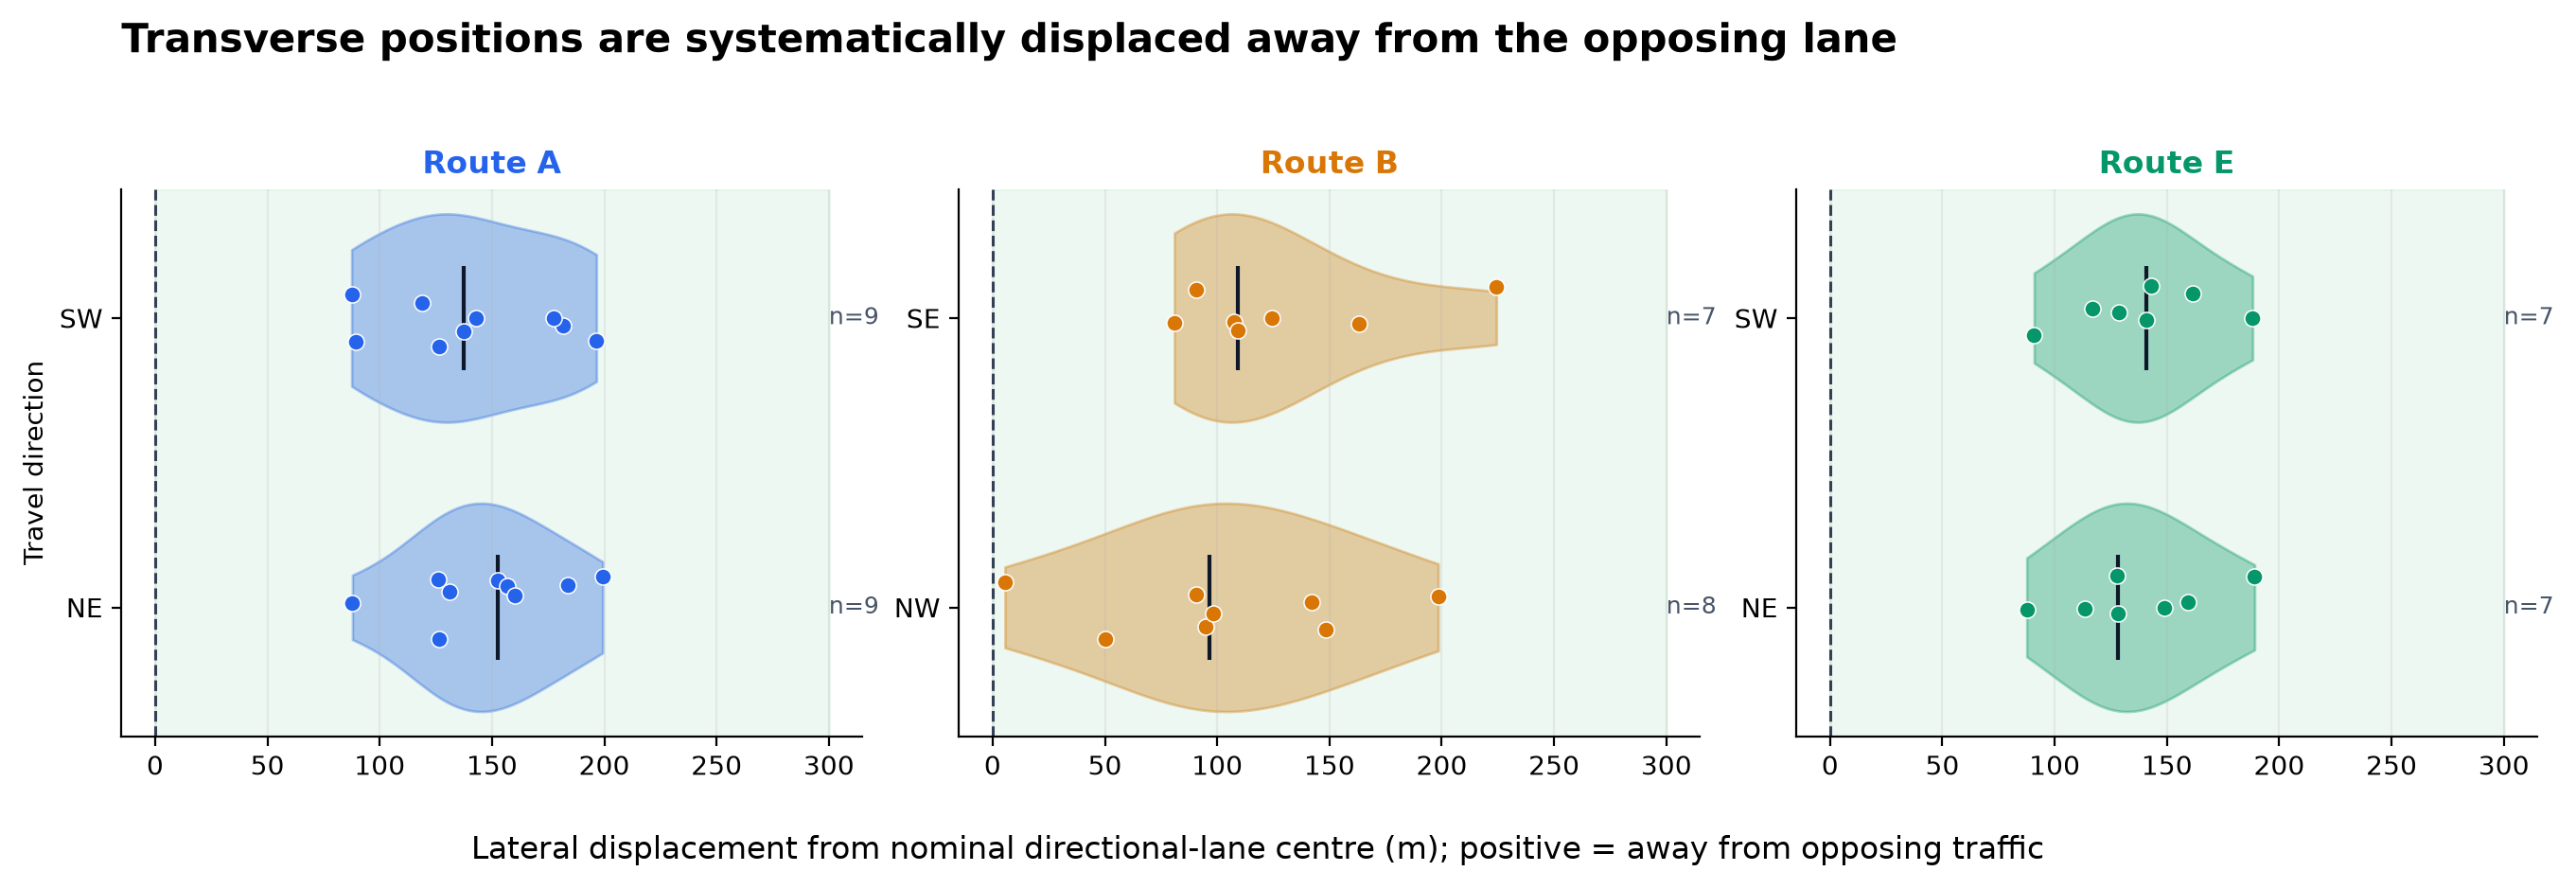

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
points = pd.read_csv(dataset_path)
lanes = pd.read_csv(Path('route_lanes.csv'))
# For each point, select the nearest compatible directional lane by position and COG, compute signed cross-track residual, then orient its sign away from the opposite lane.
# Summarize the resulting residual distribution by route_name and direction.
print(points[['trajectory_id','lat','lon','cog']].head())
print(lanes[['route_name','direction','lat','lon','nominal_bearing_deg']].head())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/transverse_lane_displacement.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "transverse_distribution",
  "insight": "For all three route families, directional-lane track positions are not symmetric around their nominal lane centres.",
  "insight_value": {
    "median_outward_displacement_m": {
      "A_NE": 152,
      "A_SW": 137,
      "B_NW": 97,
      "B_SE": 109,
      "E_NE": 128,
      "E_SW": 141
    },
    "interpretation": "positive residual is farther from the opposing lane"
  },
  "plot": {
    "plot_type": "directional_distribution",
    "title": "Asymmetric Transverse Displacement within Directional Lanes",
    "file": "visualizations/transverse_lane_displacement.png",
    "description": "For each direction, residuals are measured from its supplied nominal lane centre and oriented so positive values move away from the opposing lane."
  },
  "question": "Are vessel tracks symmetrically distributed around the nominal centre of each directional lane, or do they show a systematic transverse displacement relative to opposing traffic?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\npoints = pd.read_csv(dataset_path)\nlanes = pd.read_csv(Path('route_lanes.csv'))\n# For each point, select the nearest compatible directional lane by position and COG, compute signed cross-track residual, then orient its sign away from the opposite lane.\n# Summarize the resulting residual distribution by route_name and direction.\nprint(points[['trajectory_id','lat','lon','cog']].head())\nprint(lanes[['route_name','direction','lat','lon','nominal_bearing_deg']].head())",
  "insight_type": "group_comparison",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "route_reference_lane",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 6)

Traffic in the selected Kattegat area is organized around three recurring official-style bidirectional corridors. Their vessel composition differs clearly: Route A is tanker-dominated, whereas cargo traffic is more prominent on Routes B and E. Across the corridors, vessels also favour the outer side of their directional lane instead of being centred symmetrically between opposing flows.